# EXPERIMENT NO: 8

# GENERATION OF SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)

### Name: Ajaikumar M
### Roll No: 24BAD005
### Course: Deep Learning


**PART A — Dataset Preparation**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Load MNIST dataset

In [2]:
# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Dataset shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset shape: (60000, 28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


Display sample images

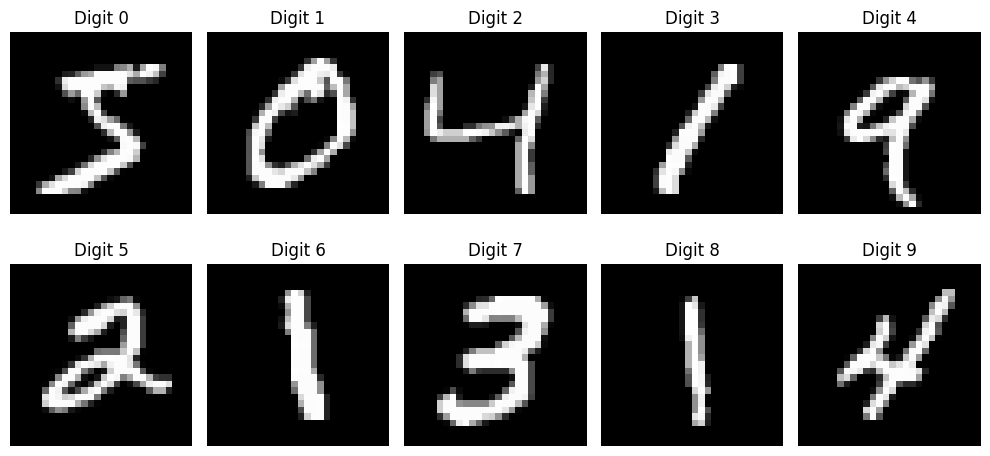

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
    plt.title(f"Digit {i}")

plt.tight_layout()
plt.show()

Normalize the images

In [4]:
# Normalize pixel values from [0, 255] to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

print("New minimum:", x_train.min())
print("New maximum:", x_train.max())

New minimum: -1.0
New maximum: 1.0


Reshape images

In [5]:
x_train = np.expand_dims(x_train, axis=-1)

print("New dataset shape:", x_train.shape)

New dataset shape: (60000, 28, 28, 1)


Prepare batches

In [6]:
BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE)
)

print("Batch size:", BATCH_SIZE)
print("Dataset prepared successfully.")

Batch size: 256
Dataset prepared successfully.


**PART B — Generator and Discriminator**

Create Generator

In [7]:
latent_dim = 100

generator = tf.keras.Sequential([
    layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(latent_dim,)),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Reshape((7, 7, 256)),

    layers.Conv2DTranspose(
        128, (5, 5),
        strides=(1, 1),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        1, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False,
        activation="tanh"
    )
])

generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Test the Generator

In [8]:
noise = tf.random.normal([1, latent_dim])

generated_image = generator(noise, training=False)

print("Generated image shape:", generated_image.shape)

Generated image shape: (1, 28, 28, 1)


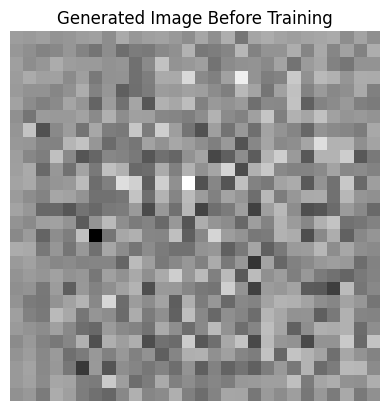

In [9]:
plt.imshow(generated_image[0, :, :, 0], cmap="gray")
plt.axis("off")
plt.title("Generated Image Before Training")
plt.show()

Create Discriminator

In [10]:
discriminator = tf.keras.Sequential([
    layers.Conv2D(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        input_shape=[28, 28, 1]
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, (5, 5),
        strides=(2, 2),
        padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Test Discriminator

In [11]:
decision = discriminator(generated_image)

print("Discriminator output:", decision.numpy())

Discriminator output: [[0.00100594]]


Define loss and optimizers

In [12]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

**PART C — GAN Training**

Define losses

In [13]:
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

Training function

In [14]:
@tf.function
def train_step(images):

    noise = tf.random.normal(
        [BATCH_SIZE, latent_dim]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

Training loop

In [16]:
EPOCHS = 10

gen_losses = []
disc_losses = []

for epoch in range(EPOCHS):

    total_gen_loss = 0
    total_disc_loss = 0
    batches = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        total_gen_loss += gen_loss
        total_disc_loss += disc_loss
        batches += 1

    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches

    gen_losses.append(float(avg_gen_loss))
    disc_losses.append(float(avg_disc_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f}"
    )

Epoch 1/10 | Generator Loss: 0.8213 | Discriminator Loss: 1.2727
Epoch 2/10 | Generator Loss: 0.8164 | Discriminator Loss: 1.2758
Epoch 3/10 | Generator Loss: 0.7995 | Discriminator Loss: 1.3037
Epoch 4/10 | Generator Loss: 0.7774 | Discriminator Loss: 1.3240
Epoch 5/10 | Generator Loss: 0.7870 | Discriminator Loss: 1.3176
Epoch 6/10 | Generator Loss: 0.7569 | Discriminator Loss: 1.3358
Epoch 7/10 | Generator Loss: 0.7740 | Discriminator Loss: 1.3308
Epoch 8/10 | Generator Loss: 0.7659 | Discriminator Loss: 1.3323
Epoch 9/10 | Generator Loss: 0.7700 | Discriminator Loss: 1.3292
Epoch 10/10 | Generator Loss: 0.7841 | Discriminator Loss: 1.3166


Plot Generator and Discriminator losses

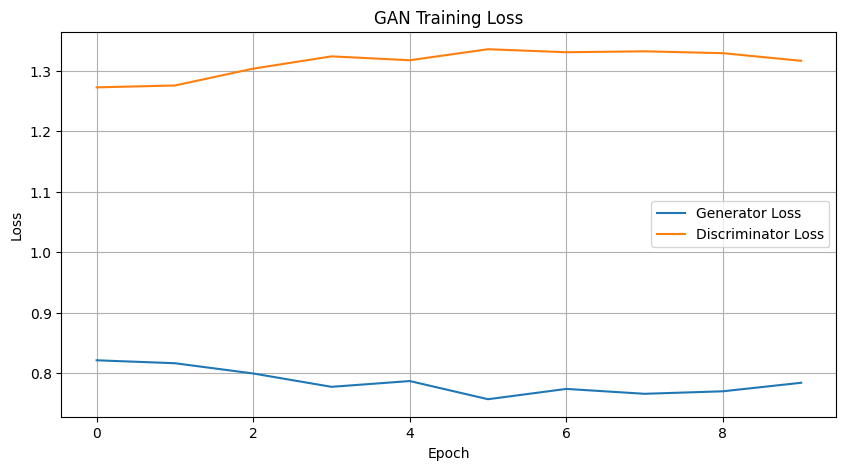

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(gen_losses, label="Generator Loss")
plt.plot(disc_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid()

plt.show()

Generate images after training

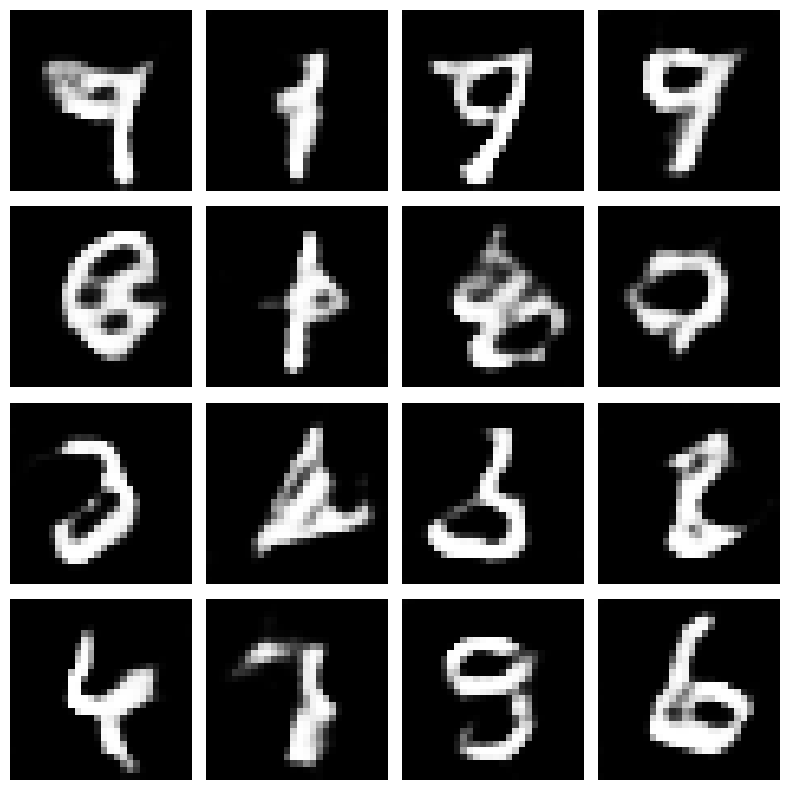

In [18]:
noise = tf.random.normal([16, latent_dim])

generated_images = generator(
    noise,
    training=False
)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

**PART D — Generate and Compare**

Compare real and generated images

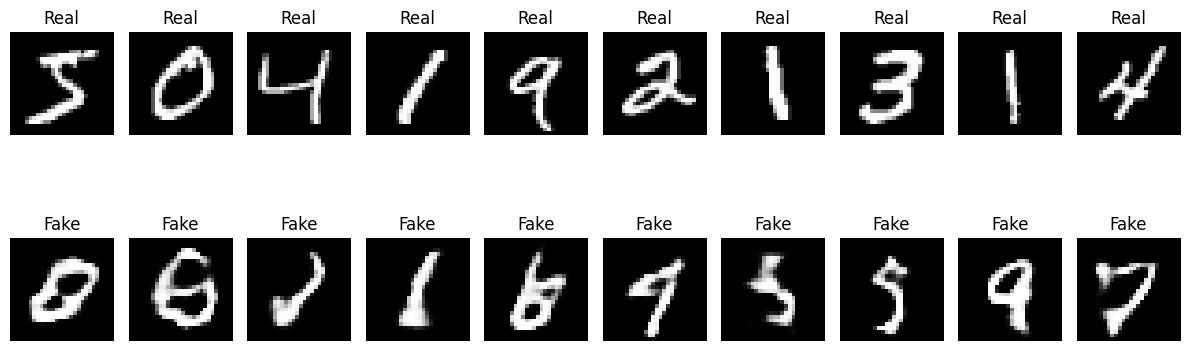

In [19]:
noise = tf.random.normal([10, latent_dim])
generated_images = generator(noise, training=False)

plt.figure(figsize=(12, 5))

# Real images
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(
        x_train[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Real")

# Generated images
for i in range(10):
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Fake")

plt.tight_layout()
plt.show()